In [76]:
import matplotlib.pyplot as plt
import random
import copy
from sklearn.datasets import make_blobs

RANDOM_SEED = 0
random.seed(RANDOM_SEED)

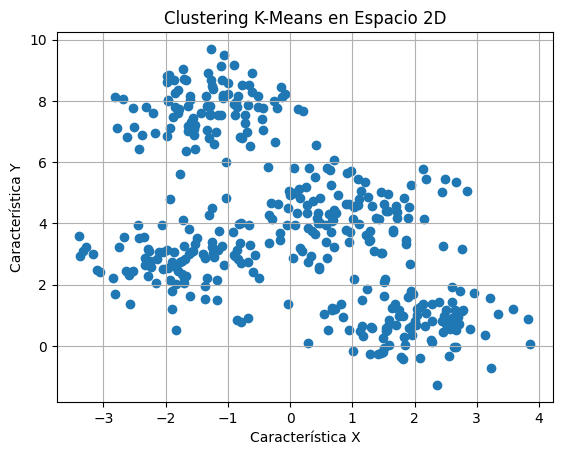

In [89]:
SAMPLES = 400
CLUSTERS_QUANTITY = random.randint(3,8)
CLUSTERS_NOISE = random.random()
X, _ = make_blobs(n_samples=SAMPLES, centers=CLUSTERS_QUANTITY, cluster_std=CLUSTERS_NOISE, random_state=RANDOM_SEED)

plt.scatter(X[:, 0], X[:, 1])
plt.title('Clustering K-Means en Espacio 2D')
plt.xlabel('Característica X')
plt.ylabel('Característica Y')
plt.grid(True)
plt.show()

# implementa el algoritmo kmeans


In [78]:
class centroide:
  def __init__ (self,x,y,grupo= 0 ):
    self.x= x
    self.y=y
    self.grupo = grupo

  def __lt__(self,otro):
    return self.grupo < otro.grupo

  def __eq__ (self,otro):
    return self.x == otro.x and self.y == otro.y

  def __repr__ (self):
    return f"Centroide número {self.grupo}, con coordenadas ({self.x},{self.y})"



class punto:
  def __init__ (self,x,y,grupo = None,distancia = 0):
    self.x = x
    self.y = y
    self.grupo = grupo
    self.distancia = distancia

  def __lt__(self,otro):
    return self.distancia < otro.distancia

  def __repr__(self):
    return f"punto({self.x}, {self.y}, distancia={self.distancia}, grupo={self.grupo})"


puntos = [None]*SAMPLES
for a in range(SAMPLES):
  puntos[a] = punto(X[a][0],X[a][1])

def cent_aleat(k):
  xmin = X[:,0].min()
  xmax = X[:,0].max()
  ymin = X[:,1].min()
  ymax = X[:,1].max()
  k_cent2 = [None]*k


  for i in range(k):
    x = random.uniform(xmin,xmax)
    y = random.uniform(ymin,ymax)
    k_cent2[i] = centroide(x,y,i+1)
  return k_cent2


def asig(k):
  k_cent = cent_aleat(k)
  anteriores = [centroide(1,1)]*k

  while anteriores != k_cent:
    k_listas=  [[] for l in range(k)]

    for p in puntos:
      lista_dis = [None]*k

      for c in range(k):
        dis = ((k_cent[c].y - p.y)**2 + (k_cent[c].x - p.x)**2)**(1/2)
        lista_dis[c] =(dis,k_cent[c].grupo)
      p_min = min(lista_dis)
      k_listas[p_min[1]-1].append(punto(p.x,p.y,p_min[1],p_min[0]))
    anteriores = k_cent.copy()

    for n in range(len(k_listas)):

      if len(k_listas[n]) > 0:
        nuevo_x = sum(q.x for q in k_listas[n]) / len(k_listas[n])
        nuevo_y = sum(q.y for q in k_listas[n]) / len(k_listas[n])
        k_cent[n] = centroide(nuevo_x, nuevo_y, n+1)
  return k_listas,k_cent
asig(6)


([[punto(1.8210497809779562, -0.372670804414575, distancia=1.223573297600767, grupo=1),
   punto(1.2971498949904932, -0.27320239439957406, distancia=1.3096831099995458, grupo=1),
   punto(1.7869562777842412, -0.14448672673671425, distancia=1.0042737727332314, grupo=1),
   punto(1.2181953067791693, 0.9372024114435222, distancia=0.7759664694724494, grupo=1),
   punto(0.8554723935894866, 1.3603033977962111, distancia=1.2465363139365915, grupo=1),
   punto(1.70388291126447, 1.2626046629187182, distancia=0.509668402244074, grupo=1),
   punto(1.3633898965557125, 1.744311073656222, distancia=1.0994848138790634, grupo=1),
   punto(2.651268262468452, 0.5441392519514899, distancia=0.7260611368240562, grupo=1),
   punto(2.173892340972678, 1.0736462986051776, distancia=0.2990070852297871, grupo=1),
   punto(2.7047060562985563, 0.40421594506926783, distancia=0.8385303109245971, grupo=1),
   punto(1.438774499974775, -0.21381911589875213, distancia=1.1878673999192677, grupo=1),
   punto(2.45021093875

# Gráfica

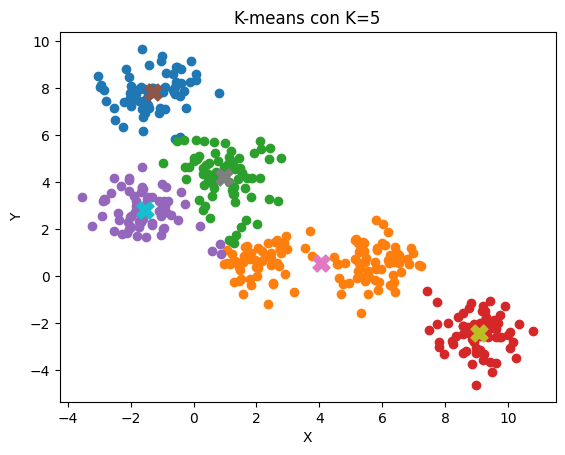

In [92]:
def graficar(k):
  k_listas, k_cent = asig(k)

  for grupo in k_listas:
    x = [p.x for p in grupo]
    y = [p.y for p in grupo]
    plt.scatter(x, y)

  for c in k_cent:
    plt.scatter(c.x, c.y, marker="X", s=150)

  plt.xlabel("X")
  plt.ylabel("Y")
  plt.title(f"K-means con K={k}")
  plt.show()
graficar(5)

# Diagrama la el puntaje obtenido para cada K, con el fin de seleccionar el mejor Inercia o Varianza Intra-Clúster (WCSS)

Es la suma de las distancias euclidianas al cuadrado desde cada punto de datos hasta el centroide de su clúster asignado. Esta es la función de costo que K-Means minimiza iterativamente.Fórmula matemática:$$WCSS = \sum_{j=1}^{k} \sum_{x \in C_j} \vert{}\vert{}x - \mu_j\vert{}\vert{}^2$$

Donde:
- $k$ es el número de clústeres.
- $C_j$ es el conjunto de puntos pertenecientes al clúster $j$.
- $\mu_j$ es el centroide del clúster $j$.
- $\vert{}\vert{}x - \mu_j\vert{}\vert{}^2$ es la distancia euclidiana al cuadrado (para evitar la raíz cuadrada y penalizar más losค่า alejados).


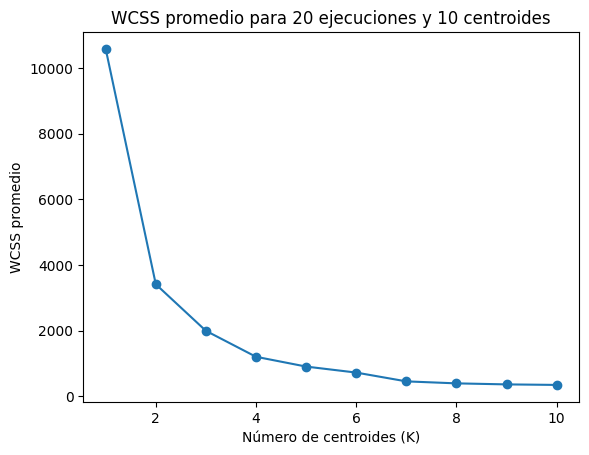

In [95]:

def WCSS(k):
  listas,cents = asig(k)
  euc = 0
  for i in range(len(listas)):
    for j in range(len(listas[i])):
      euc += (listas[i][j].x - cents[i].x)**2 + (listas[i][j].y-cents[i].y)**2
  return euc

def graficar_WCSS(k, j):

  k_valores = []
  wcss_valores = []

  for k in range(1, k + 1):
    suma = 0

    for i in range(j):
      suma += WCSS(k)

    promedio = suma / j

    k_valores.append(k)
    wcss_valores.append(promedio)

  plt.plot(k_valores, wcss_valores, marker="o")
  plt.xlabel("Número de centroides (K)")
  plt.ylabel("WCSS promedio")
  plt.title(f"WCSS promedio para {j} ejecuciones y {k} centroides")
  plt.show()
graficar_WCSS(10,20)